# 07.4 · ARIMA and SARIMA

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/07-forecasting/04-arima-sarima/lesson.ipynb)

Read the [README](README.md) first. This notebook checks the by-hand differencing and AR/MA steps, tests ShopWave's weekly revenue for stationarity, chooses a SARIMA model with ACF/PACF, checks its residuals, forecasts with intervals, and runs the 07.2 backtest.

A note on warnings: statsmodels prints optimiser notices ("non-stationary starting parameters", "failed to converge") on short series like ours. The cell below hides those specific notices so the output stays readable; we check the results ourselves with residual diagnostics and the backtest.

In [1]:
import warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.simplefilter("ignore", ConvergenceWarning)   # optimiser notices on short series; we check results ourselves
warnings.filterwarnings("ignore", message="Non-")      # "Non-stationary/Non-invertible starting parameters"
warnings.filterwarnings("ignore", category=FutureWarning, message="adfuller")   # upcoming API change notice

## 1. Differencing by hand

In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

y = pd.Series([100, 104, 110, 108, 115, 121])
pd.DataFrame({"y": y, "diff (y_t - y_t-1)": y.diff()})

,y,diff (y_t - y_t-1)
0,100,NaN
1,104,4.0
2,110,6.0
3,108,-2.0
4,115,7.0
5,121,6.0


The original wanders upwards; the differences (4, 6, −2, 7, 6) hover around a fixed level of about 4. Differencing turned a series with a trend into one with a stable mean. That is the **I** in ARIMA.

## 2. AR and MA, one step at a time

In [3]:
c, phi, y_prev = 20, 0.8, 50          # AR(1): y_t = c + phi * y_{t-1}  (+ noise)
for t in range(1, 4):
    y_next = c + phi * y_prev
    print(f"step {t}: {c} + {phi} x {y_prev:g} = {y_next:g}")
    y_prev = y_next
print("long-run mean c / (1 - phi) =", round(c / (1 - phi), 2))

step 1: 20 + 0.8 x 50 = 60
step 2: 20 + 0.8 x 60 = 68
step 3: 20 + 0.8 x 68 = 74.4
long-run mean c / (1 - phi) = 100.0


In [4]:
mu, theta, last_error = 100, 0.5, 10   # MA(1): y_t = mu + e_t + theta * e_{t-1}
print("1 step ahead:", mu + theta * last_error)   # tomorrow's e_t is unknown, so expect 0
print("2 steps ahead:", mu)                       # the shock has been forgotten

1 step ahead: 105.0
2 steps ahead: 100


An AR process **remembers values**: it drifts back towards its mean gradually. An MA process **remembers shocks**: one surprise affects the next *q* steps and then vanishes.

You can tell them apart from data with two plots:

- **ACF** (autocorrelation): correlation with lag *k*.
- **PACF** (partial autocorrelation): correlation with lag *k* *after* removing the effect of lags 1 … *k*−1.

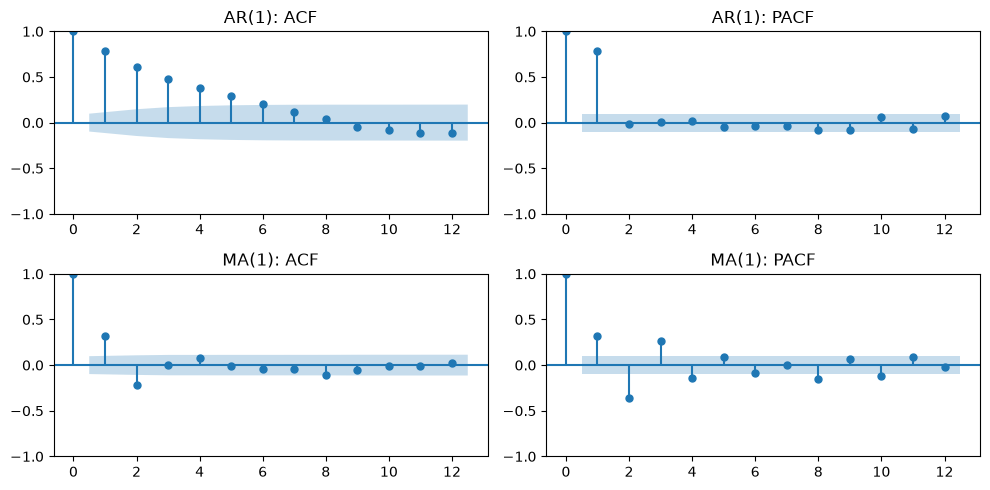

In [5]:
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

ar1 = ArmaProcess(ar=[1, -0.8]).generate_sample(400, distrvs=np.random.default_rng(0).standard_normal)
ma1 = ArmaProcess(ma=[1, 0.8]).generate_sample(400, distrvs=np.random.default_rng(1).standard_normal)
fig, axes = plt.subplots(2, 2, figsize=(10, 5))
for row, (name, s) in enumerate([("AR(1)", ar1), ("MA(1)", ma1)]):
    plot_acf(s, lags=12, ax=axes[row, 0], title=f"{name}: ACF")
    plot_pacf(s, lags=12, ax=axes[row, 1], title=f"{name}: PACF")
plt.tight_layout(); plt.show()

The fingerprints: **AR(1)** has an ACF that decays slowly and a PACF with one spike at lag 1 then nothing. **MA(1)** is the mirror image: one ACF spike at lag 1, a PACF that decays. Rule of thumb: the PACF cut-off suggests *p*, the ACF cut-off suggests *q*.

## 3. ShopWave: is it stationary?

In [6]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

# The two sheets overlap: "Year 2009-2010" runs to 9 Dec 2010, "Year 2010-2011" starts 1 Dec 2010.
older = load_retail("Year 2009-2010")
newer = load_retail("Year 2010-2011")
raw = pd.concat([older[older["InvoiceDate"] < "2010-12-01"], newer], ignore_index=True)

def clean_retail(df):
    """The standard ShopWave cleaning used from lesson 01.5 onwards."""
    out = df[~df["Invoice"].astype(str).str.startswith("C")]
    out = out[(out["Quantity"] > 0) & (out["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
    return out.assign(Revenue=out["Quantity"] * out["Price"])

sales = clean_retail(raw)
sales = sales[sales["Quantity"] < 70_000]          # two one-off orders, both cancelled the same day
END = pd.Timestamp("2011-12-04")                    # last complete week (Mon 28 Nov - Sun 4 Dec)
sales = sales[sales["InvoiceDate"] < END + pd.Timedelta(days=1)]

rev = sales.set_index("InvoiceDate")["Revenue"]
daily = rev.resample("D").sum()                     # every calendar day, 0 when closed
weekly = rev.resample("W").sum()                    # weeks end on Sunday
monthly = rev.resample("ME").sum()                  # month-end dates
monthly = monthly[monthly.index <= "2011-11-30"]    # December 2011 has only 4 days: drop it
print(f"{len(sales):,} order lines, {daily.index[0].date()} to {daily.index[-1].date()}")
print(f"{len(daily)} days, {len(weekly)} weeks, {len(monthly)} months")

H = 5                                                   # forecast 5 weeks ahead
ORIGINS = pd.date_range("2011-04-03", periods=8, freq="4W-SUN")      # 3 Apr ... 16 Oct 2011

def backtest(forecast_fn, series=None, origins=ORIGINS, h=H):
    """Rolling-origin backtest: at each origin, fit on the past, forecast h weeks, score MAE."""
    series = weekly if series is None else series
    rows = []
    for origin in origins:
        train = series[series.index <= origin]
        test = series[series.index > origin].iloc[:h]
        pred = np.asarray(forecast_fn(train, len(test)))
        rows.append({"origin": origin.date(), "MAE": np.abs(test.values - pred).mean()})
    return pd.DataFrame(rows)

def naive(train, h):          return np.repeat(train.iloc[-1], h)
def mean_fc(train, h):        return np.repeat(train.mean(), h)
def seasonal_naive(train, h): return train.iloc[-52:-52 + h].values
def drift(train, h):
    slope = (train.iloc[-1] - train.iloc[0]) / (len(train) - 1)
    return train.iloc[-1] + slope * np.arange(1, h + 1)

import warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX

def sarima(train, h):
    """SARIMA(1,0,1)(0,1,0,52) with a constant: last year's week, corrected by recent errors."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")      # statsmodels start-value notices, not errors
        model = SARIMAX(train, order=(1, 0, 1), seasonal_order=(0, 1, 0, 52), trend="c").fit(disp=False)
    return model.forecast(h).values

768,341 order lines, 2009-12-01 to 2011-12-04
734 days, 105 weeks, 24 months


In [7]:
from statsmodels.tsa.stattools import adfuller

for name, s in [("weekly", weekly), ("weekly, 1st difference", weekly.diff().dropna()),
                ("weekly, 52-week difference", weekly.diff(52).dropna())]:
    stat, p = adfuller(s)[:2]
    print(f"{name:<28} ADF statistic {stat:6.2f}   p-value {p:.4f}")

weekly                       ADF statistic  -3.62   p-value 0.0054
weekly, 1st difference       ADF statistic  -8.61   p-value 0.0000
weekly, 52-week difference   ADF statistic  -8.16   p-value 0.0000


The **ADF test** asks: "does this series have a unit root (a level that wanders without coming back)?" A small p-value (below 0.05) says no, the series is stationary *in that sense*.

ShopWave's raw weekly revenue already passes (p well below 0.05), because its level does not wander: the trend is flat, as 07.1 showed. But ADF does not test for seasonality, and the yearly pattern is obviously there. So we take a **seasonal difference** (this week minus the same week last year). What is left is "how different is this year from last year", which is what the ARMA part will model.

53 weeks after seasonal differencing (the first 52 are used up)


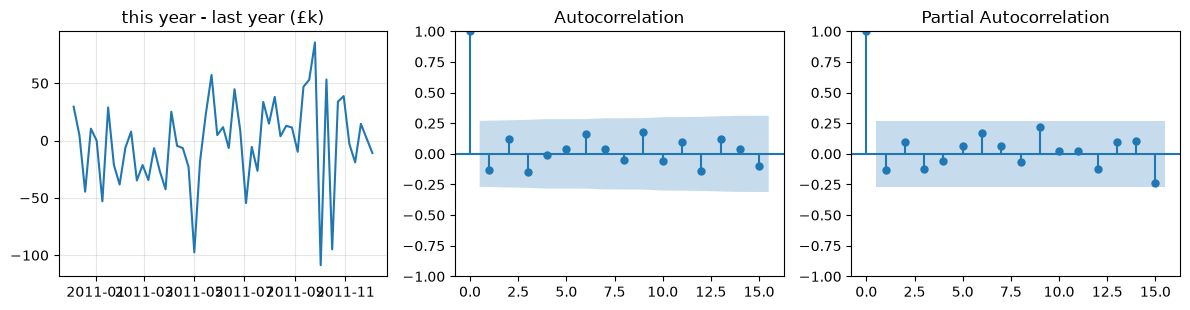

In [8]:
sd = weekly.diff(52).dropna()
print(f"{len(sd)} weeks after seasonal differencing (the first 52 are used up)")
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
axes[0].plot(sd.index, sd / 1000); axes[0].set_title("this year - last year (£k)"); axes[0].grid(alpha=.3)
plot_acf(sd, lags=15, ax=axes[1]); plot_pacf(sd, lags=15, ax=axes[2], method="ywm")
plt.tight_layout(); plt.show()

In [9]:
from statsmodels.tsa.stattools import acf, pacf
print("ACF  lags 1-3:", acf(sd, nlags=3)[1:].round(2))
print("PACF lags 1-3:", pacf(sd, nlags=3, method="ywm")[1:].round(2))
print("95% band: +/-", round(1.96 / np.sqrt(len(sd)), 2))

ACF  lags 1-3: [-0.14  0.12 -0.15]
PACF lags 1-3: [-0.14  0.1  -0.12]
95% band: +/- 0.27


After seasonal differencing only 53 weeks remain, so the 95% band is wide (about ±0.27). Every bar in both plots sits **inside** the band: lag 1 is the largest, at −0.14. The honest reading is "no detectable pattern left once last year is subtracted", which points at the simplest model of all: SARIMA(0,0,0)(0,1,0)₅₂ with a constant, which is seasonal naive plus an average year-on-year change.

To see what happens when you ask for more anyway, we fit **SARIMA(1,0,1)(0,1,0)₅₂** with a constant: seasonal difference once, then one AR and one MA term on what is left.

## 4. Fit, check, forecast

In [10]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

train = weekly[weekly.index <= "2011-10-16"]
fit = SARIMAX(train, order=(1, 0, 1), seasonal_order=(0, 1, 0, 52), trend="c").fit(disp=False)
print(fit.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept  -3755.0218    1.7e+06     -0.002      0.998   -3.34e+06    3.33e+06
ar.L1       4.939e-05    453.322   1.09e-07      1.000    -888.494     888.494
ma.L1         -0.0003    453.299  -5.76e-07      1.000    -888.450     888.450
sigma2      1.543e+09   2453.363   6.29e+05      0.000    1.54e+09    1.54e+09


Read the table: `ar.L1` is φ (how much of last week's year-on-year difference carries into this week), `ma.L1` is θ, `intercept` is the constant (the average year-on-year change per week), `sigma2` is the noise variance.

Here φ and θ come out at essentially **zero**, with standard errors in the hundreds: the AR and MA terms found nothing, exactly as the ACF and PACF predicted. With 46 usable weeks after differencing there is not enough data to pin them down. The fitted model is, in effect, "same week last year, minus about £3.8k". Asking for a more complex model did not make it more complex; the data refused.

**Residual check.** If the model captured the pattern, its residuals should look like noise: no autocorrelation left. The **Ljung-Box test** checks this; a large p-value means "no evidence of leftover pattern".

    lb_stat  lb_pvalue
4     2.910      0.573
8     3.602      0.891
12    7.803      0.800


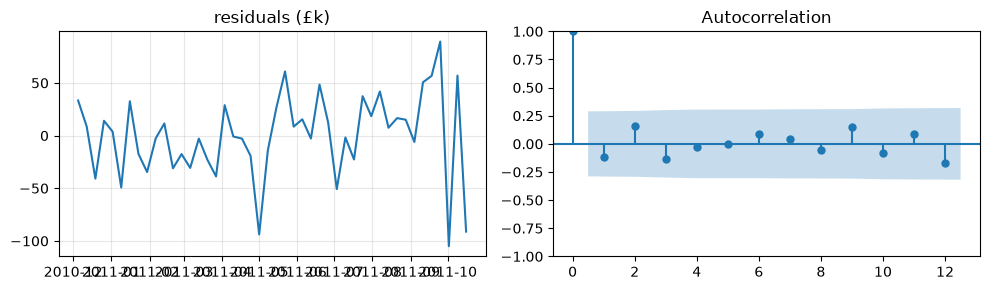

In [11]:
from statsmodels.stats.diagnostic import acorr_ljungbox
resid = fit.resid[52:]                       # the first season is consumed by differencing
print(acorr_ljungbox(resid, lags=[4, 8, 12]).round(3))
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(resid.index, resid / 1000); ax[0].set_title("residuals (£k)"); ax[0].grid(alpha=.3)
plot_acf(resid, lags=12, ax=ax[1]); plt.tight_layout(); plt.show()

In [12]:
fc = fit.get_forecast(steps=H)
out = pd.DataFrame({"forecast": fc.predicted_mean, "lower 95%": fc.conf_int().iloc[:, 0],
                    "upper 95%": fc.conf_int().iloc[:, 1]})
out["actual"] = weekly.reindex(out.index)
(out / 1000).round(1)

,forecast,lower 95%,upper 95%,actual
2011-10-23,217.1,140.2,294.1,254.8
2011-10-30,194.0,117.0,271.0,236.5
2011-11-06,258.8,181.9,335.8,259.4
2011-11-13,279.0,202.0,355.9,263.7
2011-11-20,257.9,180.9,334.8,276.2


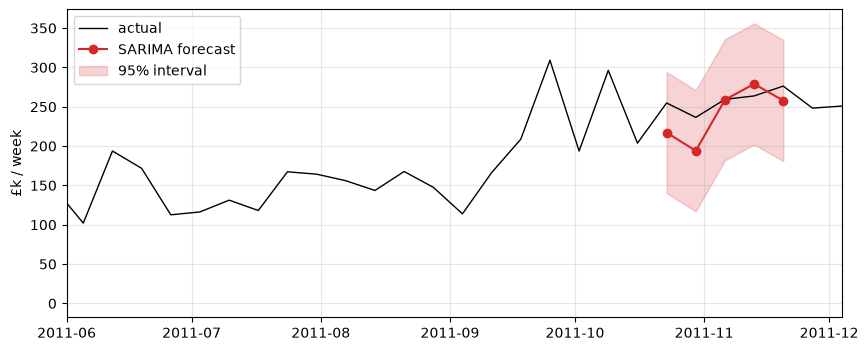

In [13]:
plt.figure(figsize=(10, 4))
plt.plot(weekly.index, weekly / 1000, color="black", linewidth=1, label="actual")
plt.plot(out.index, out["forecast"] / 1000, color="tab:red", marker="o", label="SARIMA forecast")
plt.fill_between(out.index, out["lower 95%"] / 1000, out["upper 95%"] / 1000, color="tab:red", alpha=.2,
                 label="95% interval")
plt.xlim(pd.Timestamp("2011-06-01"), weekly.index[-1]); plt.ylabel("£k / week")
plt.legend(); plt.grid(alpha=.3); plt.show()

The interval is the most useful thing SARIMA gives you that the baselines did not: a **range** for each week. Buyers can plan to the upper bound for best-sellers they cannot afford to run out of, and to the forecast for everything else.

## 5. The backtest

In [14]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

def holt_winters(train, h):
    """Additive Holt-Winters, seeded with the first year as the starting seasonal pattern."""
    first = train.iloc[:52]
    model = ExponentialSmoothing(
        train, trend="add", damped_trend=True, seasonal="add", seasonal_periods=52,
        initialization_method="known", initial_level=first.mean(), initial_trend=0.0,
        initial_seasonal=(first - first.mean()).values).fit()
    return model.forecast(h).values

models = [("seasonal naive", seasonal_naive), ("Holt-Winters", holt_winters), ("SARIMA", sarima)]
per_origin = pd.DataFrame({name: backtest(fn)["MAE"] for name, fn in models}).set_axis(
    [o.date() for o in ORIGINS])
print((per_origin.mean() / 1000).round(1).rename("mean MAE £k"))
(per_origin / 1000).round(1)

seasonal naive    32.4
Holt-Winters      34.7
SARIMA            34.6
Name: mean MAE £k, dtype: float64


,seasonal naive,Holt-Winters,SARIMA
2011-04-03,29.9,21.7,22.1
2011-05-01,22.9,46.1,34.0
2011-05-29,25.2,27.0,27.9
2011-06-26,27.0,26.4,26.9
2011-07-24,16.1,20.1,24.3
2011-08-21,41.3,41.7,44.4
2011-09-18,75.2,72.3,74.1
2011-10-16,21.9,21.9,22.8


SARIMA is close to seasonal naive but does not beat it on average (£34.6k vs £32.4k). Again: with one year of year-on-year differences to learn from, the AR and MA terms have nothing to find, and the constant (an average year-on-year change estimated from a few dozen weeks) adds a little noise of its own. The honest takeaway for ShopWave is that **last year's same week is a very strong forecast**, and the value of SARIMA here is mostly the prediction interval, not extra accuracy.

## Quiz answers

1. A stationary series has a stable mean and variance and no pattern tied to the calendar. Many models (ARMA) assume it.
2. Differences of `[50, 53, 57, 56]` are **3, 4, −1**.
3. AR(1) with c = 10, φ = 0.5, last value 40: 10 + 0.5 × 40 = **30**.
4. An ACF that decays slowly with a PACF that cuts off after lag 2 suggests AR(2).
5. In SARIMA(1,0,1)(0,1,0)₅₂: one AR term, no ordinary differencing, one MA term; seasonal part: no seasonal AR, one **seasonal difference** at lag 52, no seasonal MA.

**Next:** [07.5 Forecasting with machine learning](../05-ml-forecasting/)